In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================
# Step 1: Load the Dataset (Using your local CSV)
# ==========================================
# Replace "diamonds.csv" with your actual file path if it's in a different folder
df = pd.read_csv("diamonds.csv")

print("--- Step 1: First few rows ---")
print(df.head())
print("\nDataset Shape:", df.shape)

# Data Cleaning: Drop an unneeded index column if your CSV has one (like 'Unnamed: 0')
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Drop rows with missing values to ensure calculations run smoothly
df = df.dropna()

--- Step 1: First few rows ---
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75

Dataset Shape: (53940, 10)


In [2]:
# ==========================================
# Step 2: Grouping and Aggregation
# ==========================================
print("\n--- Step 2.1: Group by Cut Aggregations ---")
cut_aggregations = df.groupby("cut", observed=False).agg(
    average_price=("price", "mean"),
    total_carat=("carat", "sum"),
    max_depth=("depth", "max"),
)
print(cut_aggregations)

print("\n--- Step 2.2: Median Price by Cut and Color ---")
median_price_by_cut_color = (
    df.groupby(["cut", "color"], observed=False)["price"].median().unstack()
)
print(median_price_by_cut_color)


--- Step 2.1: Group by Cut Aggregations ---
           average_price  total_carat  max_depth
cut                                             
Fair         4358.757764      1684.28       79.0
Good         3928.864452      4166.10       67.0
Ideal        3457.541970     15146.84       66.7
Premium      4584.257704     12300.95       63.0
Very Good    3981.759891      9742.70       64.9

--- Step 2.2: Median Price by Cut and Color ---
color           D       E       F       G       H       I       J
cut                                                              
Fair       3730.0  2956.0  3035.0  3057.0  3816.0  3246.0  3302.0
Good       2728.5  2420.0  2647.0  3340.0  3468.5  3639.5  3733.0
Ideal      1576.0  1437.0  1775.0  1857.5  2278.0  2659.0  4096.0
Premium    2009.0  1928.0  2841.0  2745.0  4511.0  4640.0  5063.0
Very Good  2310.0  1989.5  2471.0  2437.0  3734.0  3888.0  4113.0


In [3]:
# ==========================================
# Step 3: Applying Custom Functions
# ==========================================
# 3.1 Custom function for price-to-carat ratio applied to each row
def calc_ratio(row):
    return row["price"] / row["carat"]


df["price_to_carat_ratio"] = df.apply(calc_ratio, axis=1)

print("\n--- Step 3.1: Dataframe with Price-to-Carat Ratio ---")
print(df[["carat", "price", "price_to_carat_ratio"]].head())


# 3.2 Top 3 highest price-to-carat ratio diamonds for each color
def get_top_3_ratios(group):
    return group.nlargest(3, "price_to_carat_ratio")


top_3_by_color = df.groupby("color", observed=False).apply(get_top_3_ratios)

print("\n--- Step 3.2: Top 3 Highest Ratios per Color ---")
print(
    top_3_by_color[
        ["color", "carat", "price", "price_to_carat_ratio"]
    ].head(9)
)


# 3.3 Aggregate mean ratio for each color after resetting index
top_3_reset = top_3_by_color.reset_index(drop=True)
mean_ratio_by_color = (
    top_3_reset.groupby("color", observed=False)["price_to_carat_ratio"]
    .mean()
    .reset_index()
)

print("\n--- Step 3.3: Mean Ratio of Top 3 Diamonds per Color ---")
print(mean_ratio_by_color)


--- Step 3.1: Dataframe with Price-to-Carat Ratio ---
   carat  price  price_to_carat_ratio
0   0.23    326           1417.391304
1   0.21    326           1552.380952
2   0.23    327           1421.739130
3   0.29    334           1151.724138
4   0.31    335           1080.645161

--- Step 3.2: Top 3 Highest Ratios per Color ---
            color  carat  price  price_to_carat_ratio
color                                                
D     27635     D   1.04  18542          17828.846154
      27530     D   1.07  18279          17083.177570
      27226     D   1.03  17590          17077.669903
E     27677     E   1.28  18700          14609.375000
      27139     E   1.21  17353          14341.322314
      25986     E   1.09  15193          13938.532110
F     27591     F   1.33  18435          13860.902256
      27671     F   1.42  18682          13156.338028
      26166     F   1.21  15497          12807.438017

--- Step 3.3: Mean Ratio of Top 3 Diamonds per Color ---
  color  price_

/var/folders/hw/mr_tqyws2jx9c63s7wfqf4280000gn/T/ipykernel_75033/4223489160.py:20: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_3_by_color = df.groupby("color", observed=False).apply(get_top_3_ratios)


In [5]:

# ==========================================
# Step 4: Transforming Data
# ==========================================
# 4.1 Standardize price within each cut group
df["standardized_price"] = df.groupby("cut", observed=False)["price"].transform(
    lambda x: (x - x.mean()) / x.std()
)

# 4.2 Normalize price within each cut group
df["normalized_price"] = df.groupby("cut", observed=False)["price"].transform(
    lambda x: (x - x.min()) / (x.max() - x.min())
)

# 4.3 Filter out diamonds below the 25th percentile of carat weight within each cut group
# First, calculate the 25th percentile cutoff for each group and broadcast it back to the rows
carat_25th = df.groupby("cut", observed=False)["carat"].transform(lambda x: x.quantile(0.25))

# Filter rows where the carat weight is greater than or equal to that group's cutoff
df_filtered_carat = df[df["carat"] >= carat_25th]

print("\n--- Step 4: Transformation Sample ---")
print(
    df[
        ["cut", "price", "standardized_price", "normalized_price", "carat"]
    ].head()
)
print(f"\nOriginal rows: {len(df)} | Rows after 25th percentile filter: {len(df_filtered_carat)}")


--- Step 4: Transformation Sample ---
       cut  price  standardized_price  normalized_price  carat
0    Ideal    326           -0.822272          0.000000   0.23
1  Premium    326           -0.979089          0.000000   0.21
2     Good    327           -0.978345          0.000000   0.23
3  Premium    334           -0.977249          0.000433   0.29
4     Good    335           -0.976172          0.000433   0.31

Original rows: 53940 | Rows after 25th percentile filter: 41033


encountered this error:
```
TypeError                                 Traceback (most recent call last)
Cell In[4], line 15
     10 df["normalized_price"] = df.groupby("cut", observed=False)["price"].transform(
     11     lambda x: (x - x.min()) / (x.max() - x.min())
     12 )
     14 # 4.3 Filter out diamonds below the 25th percentile of carat weight within each cut group
---> 15 df_filtered_carat = df.groupby("cut", observed=False).filter(
     16     lambda x: x["carat"] >= x["carat"].quantile(0.25)
     17 )
     19 print("\n--- Step 4: Transformation Sample ---")
     20 print(
     21     df[
     22         ["cut", "price", "standardized_price", "normalized_price", "carat"]
     23     ].head()
     24 )

File /Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pandas/core/groupby/generic.py:1932, in DataFrameGroupBy.filter(self, func, dropna, *args, **kwargs)
   1929             indices.append(self._get_index(name))
   1930     else:
   1931         # non scalars aren't allowed
-> 1932         raise TypeError(
   1933             f"filter function returned a {type(res).__name__}, "
   1934             "but expected a scalar bool"
   1935         )
   1937 return self._apply_filter(indices, dropna)

TypeError: filter function returned a Series, but expected a scalar bool
```

found a fix with:
```
# 4.3 Filter out diamonds below the 25th percentile of carat weight within each cut group
# First, calculate the 25th percentile cutoff for each group and broadcast it back to the rows
carat_25th = df.groupby("cut", observed=False)["carat"].transform(lambda x: x.quantile(0.25))

# Filter rows where the carat weight is greater than or equal to that group's cutoff
df_filtered_carat = df[df["carat"] >= carat_25th]
```

In [6]:
# ==========================================
# Step 5: Filtering Data
# ==========================================
# Filter to include color groups where standard deviation of price > 1000
df_filtered_color = df.groupby("color", observed=False).filter(
    lambda x: x["price"].std() > 1000
)

print("\n--- Step 5: Filtering Color Groups ---")
print(f"Original colors available: {df['color'].unique().tolist()}")
print(
    f"Colors remaining after SD > 1000 filter: {df_filtered_color['color'].unique().tolist()}"
)


--- Step 5: Filtering Color Groups ---
Original colors available: ['E', 'I', 'J', 'H', 'F', 'G', 'D']
Colors remaining after SD > 1000 filter: ['E', 'I', 'J', 'H', 'F', 'G', 'D']


In [7]:
# ==========================================
# Step 6: Pivot Table
# ==========================================
pivot_summary = df.pivot_table(
    values="price",
    index="cut",
    columns="clarity",
    aggfunc="mean",
    fill_value=0,
    observed=False,
)

print("\n--- Step 6: Pivot Table (Average Price by Cut and Clarity) ---")
print(pivot_summary)


--- Step 6: Pivot Table (Average Price by Cut and Clarity) ---
clarity             I1           IF          SI1          SI2          VS1  \
cut                                                                          
Fair       3703.533333  1912.333333  4208.279412  5173.916309  4165.141176   
Good       3596.635417  4098.323944  3689.533333  4580.260870  3801.445988   
Ideal      4335.726027  2272.913366  3752.118169  4755.952656  3489.744497   
Premium    3947.331707  3856.143478  4455.269371  5545.936928  4485.462041   
Very Good  4078.226190  4396.216418  3932.391049  4988.688095  3805.353239   

clarity            VS2         VVS1         VVS2  
cut                                               
Fair       4174.724138  3871.352941  3349.768116  
Good       4262.236196  2254.774194  3079.108392  
Ideal      3284.550385  2468.129458  3250.290100  
Premium    4550.331248  2831.206169  3795.122989  
Very Good  4215.759552  2459.441065  3037.765182  


/var/folders/hw/mr_tqyws2jx9c63s7wfqf4280000gn/T/ipykernel_75033/3691552425.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


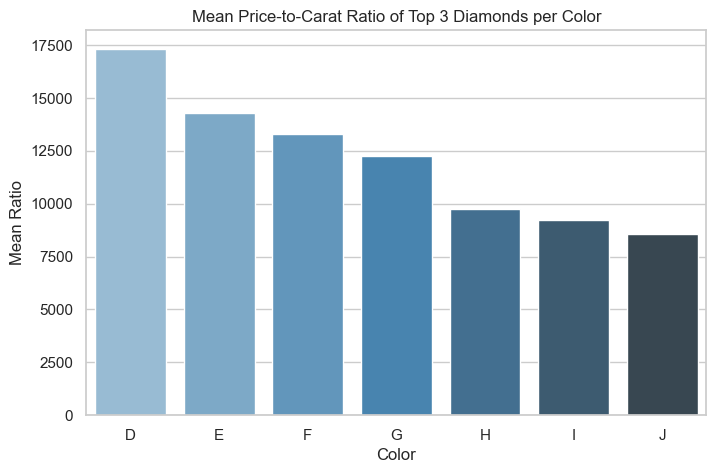

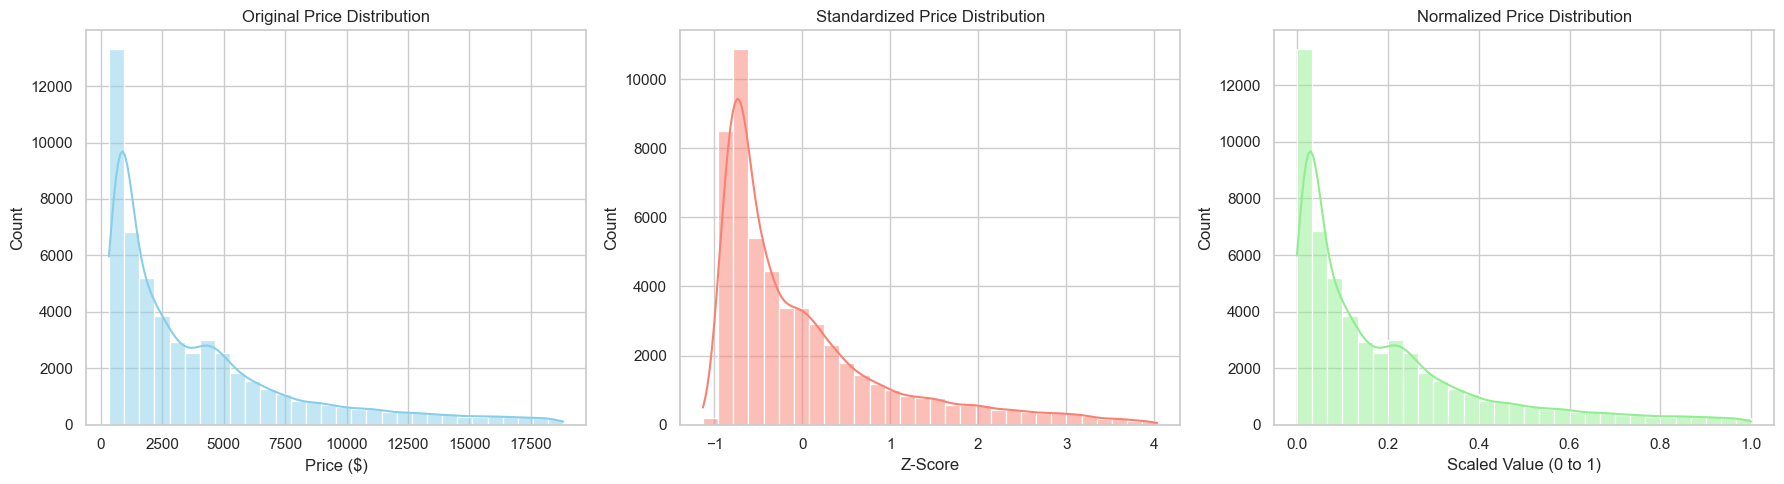

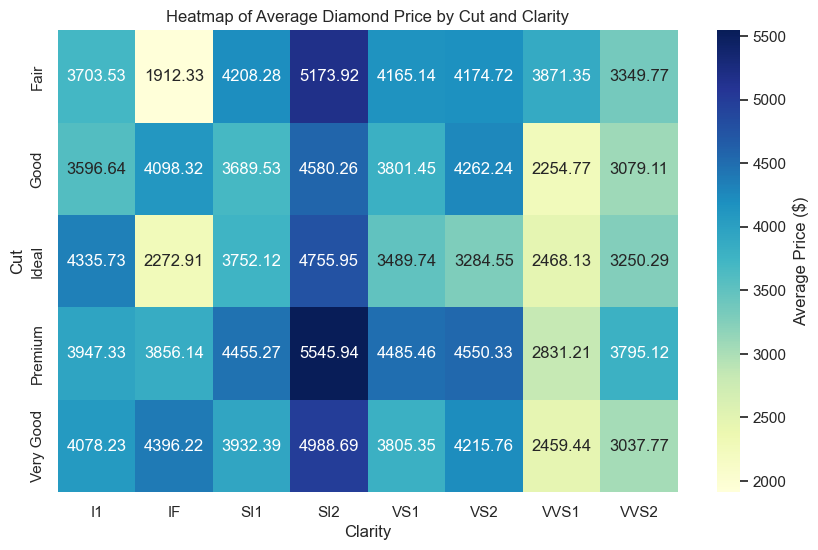

In [8]:
# ==========================================
# Step 9: Data Visualization
# ==========================================
# Set up seaborn style for clean visuals
sns.set_theme(style="whitegrid")

# Plot 1: Bar plot of mean price_to_carat_ratio for Step 3.3
plt.figure(figsize=(8, 5))
sns.barplot(
    data=mean_ratio_by_color,
    x="color",
    y="price_to_carat_ratio",
    palette="Blues_d",
)
plt.title("Mean Price-to-Carat Ratio of Top 3 Diamonds per Color")
plt.xlabel("Color")
plt.ylabel("Mean Ratio")
plt.show()

# Plot 2: Histograms comparing original, standardized, and normalized prices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original Price
sns.histplot(df["price"], bins=30, ax=axes[0], color="skyblue", kde=True)
axes[0].set_title("Original Price Distribution")
axes[0].set_xlabel("Price ($)")

# Standardized Price
sns.histplot(
    df["standardized_price"], bins=30, ax=axes[1], color="salmon", kde=True
)
axes[1].set_title("Standardized Price Distribution")
axes[1].set_xlabel("Z-Score")

# Normalized Price
sns.histplot(
    df["normalized_price"], bins=30, ax=axes[2], color="lightgreen", kde=True
)
axes[2].set_title("Normalized Price Distribution")
axes[2].set_xlabel("Scaled Value (0 to 1)")

plt.tight_layout()
plt.show()

# Plot 3: Heatmap of the pivot table
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_summary, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Average Price ($)'})
plt.title("Heatmap of Average Diamond Price by Cut and Clarity")
plt.xlabel("Clarity")
plt.ylabel("Cut")
plt.show()